In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

# 1. Load data (download emails.csv from the Kaggle link first)

In [2]:
df = pd.read_csv("emails.csv")
print(df.shape)
print(df["Prediction"].value_counts())   # 0 = Not Spam (normal), 1 = Spam (abnormal)

(5172, 3002)
Prediction
0    3672
1    1500
Name: count, dtype: int64


# 2. Features:

In [4]:
X = df.drop(columns=["Email No.", "Prediction"])
y = df["Prediction"]

In [5]:
# 3. Train/test split + scaling (KNN and SVM are distance-based, so scaling matters)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
 
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Models

In [6]:
models = {
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (linear)": SVC(kernel="linear", C=1.0),
}

# Train, Evaluate


=== KNN (k=5) ===
              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


=== SVM (linear) ===
              precision    recall  f1-score   support

    Not Spam       0.97      0.96      0.97       735
        Spam       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



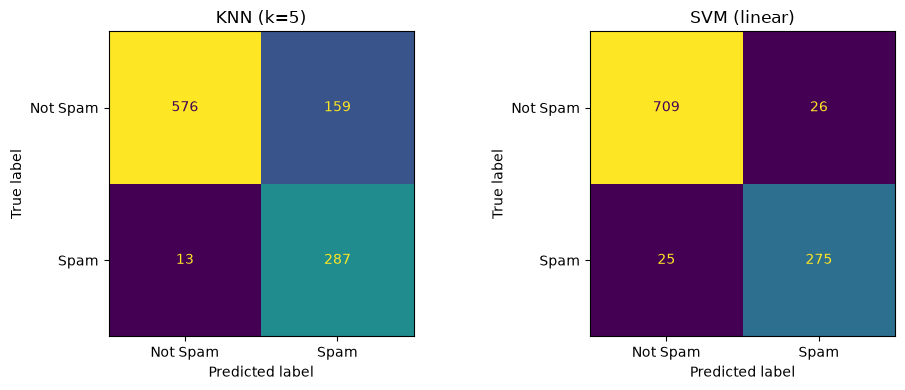

In [7]:
results = []
fig, axes = plt.subplots(1, len(models), figsize=(10, 4))
 
for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
 
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })
 
    print(f"\n=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=["Not Spam", "Spam"]))
 
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["Not Spam", "Spam"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
 
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

# Comparison Table

In [8]:
print("\n=== Performance Comparison ===")
print(pd.DataFrame(results).round(4).to_string(index=False))


=== Performance Comparison ===
       Model  Accuracy  Precision  Recall     F1
   KNN (k=5)    0.8338     0.6435  0.9567 0.7694
SVM (linear)    0.9507     0.9136  0.9167 0.9151
